### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DVFM = data.copy()
DVFM = DVFM[DVFM['category']=='vegetables and fruits']
DVFM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448
5,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,484.85,0.2724
8,1/15/2008,Magway,Magway,Magway,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,181.82,0.1021
13,1/15/2008,Magway,Pakokku,Pakhangyi,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,242.42,0.1362
48,1/15/2008,Shan (North),Hopang,Kaung Ming Sang,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,1190.58,0.6689


In [13]:
DVFM = DVFM[['date', 'price']]
DVFM['date'] = pd.to_datetime(DVFM['date'])
mask = (DVFM['date']>=obv_st_date) & (DVFM['date']<=obv_end_date)
DVFM = DVFM.loc[mask]
DVFM = DVFM.set_index('date')
DVFM.head()

,price
date,
2008-01-15,969.70
2008-01-15,484.85
2008-01-15,181.82
2008-01-15,242.42
2008-01-15,1190.58


In [14]:
DVFM = DVFM.resample('MS').mean()
DVFM.head()

,price
date,
2008-01-01,859.156923
2008-02-01,795.805385
2008-03-01,848.876923
2008-04-01,694.560000
2008-05-01,767.373333


In [15]:
DVFM.shape

(169, 1)

In [16]:
price = DVFM['price']
date = DVFM.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DVFM = scaler.fit_transform(DVFM)
DVFM = pd.DataFrame(DVFM)
DVFM.head()

,0
0,0.310563
1,0.262275
2,0.302727
3,0.185104
4,0.240604


In [19]:
DVFM['date']=date
DVFM = DVFM.set_index('date')
DVFM.columns=['price']
DVFM.head()

,price
date,
2008-01-01,0.310563
2008-02-01,0.262275
2008-03-01,0.302727
2008-04-01,0.185104
2008-05-01,0.240604


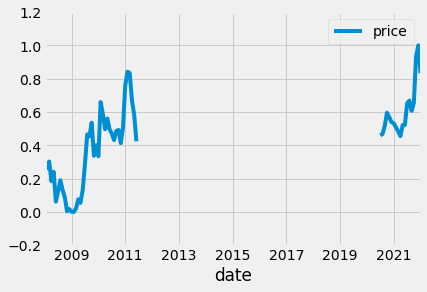

In [20]:
DVFM.plot(grid=True)
plt.show()

There is missing data.

##### Filling data with linear interpolation

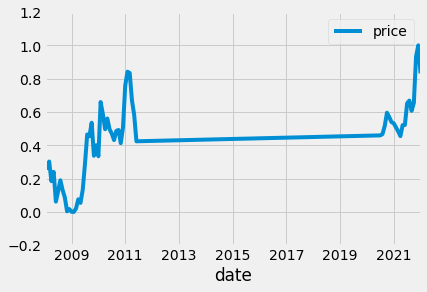

In [21]:
DVFM = DVFM.interpolate(method='linear')
DVFM.plot(grid=True)
plt.show()

There is a like positive trend.

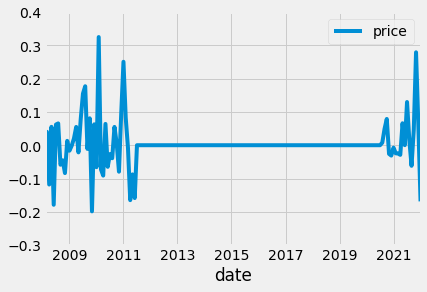

In [23]:
DVFM_diff1 = DVFM.diff(1).dropna()
DVFM_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [24]:
RW_DVFM= adfuller(DVFM_diff1)
RW_DVFM[1] # print P-value. If p-value<5%, reject null hypothesis

8.506435435579e-05

##### Plotting ACF and PACF

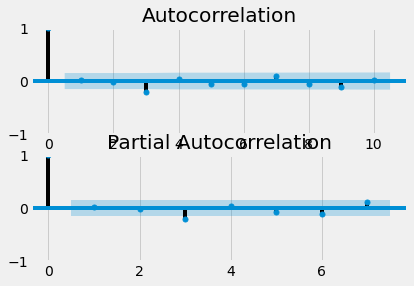

In [25]:
fig, axes=plt.subplots(2,1)
plot_acf(DVFM_diff1, lags=10, ax=axes[0])
plot_pacf(DVFM_diff1, lags=7, ax=axes[1])
plt.show()

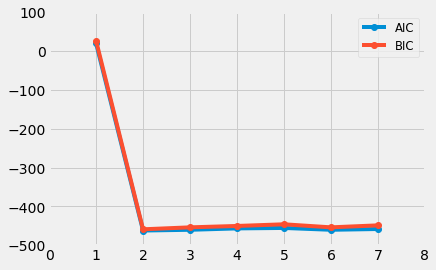

In [26]:
AIC, BIC = AIC_BIC_withOrderRange(DVFM, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [27]:
AIC, BIC

(array([ 220.35223425,   19.7817214 , -461.99473391, -460.07695214,
        -456.52251421, -455.36697059, -460.07640848, -458.07689219]),
 array([ 223.48213297,   26.04151883, -458.87076993, -453.82902418,
        -450.26271678, -445.97727445, -453.82848052, -448.70500025]))

We will run again 2:(0,1,0), 3:(0,1,1), 6:(1,1,0), 7:(1,1,1)

In [28]:
mod_orders = [
    (0,1,0),
    (0,1,1),
    (1,1,0),
    (1,1,1)
]

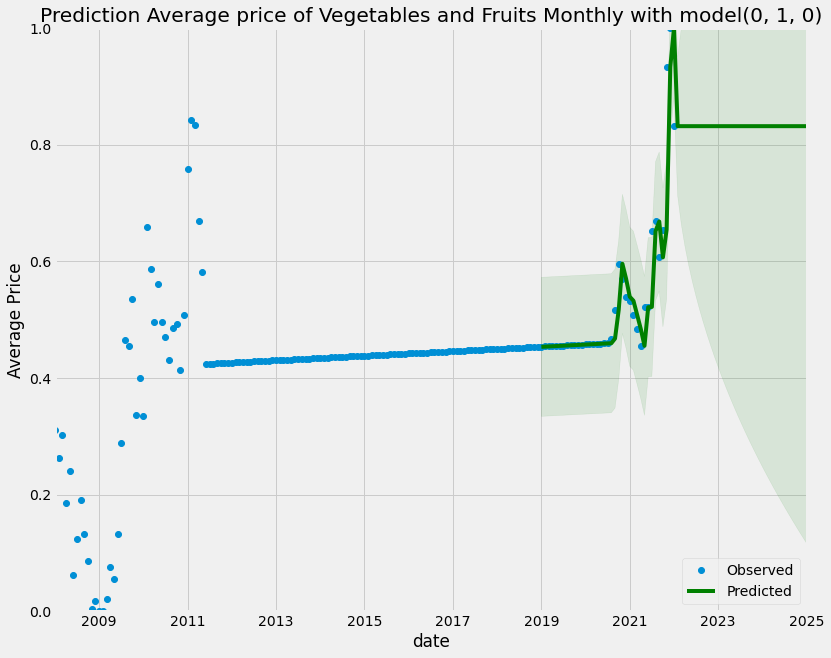

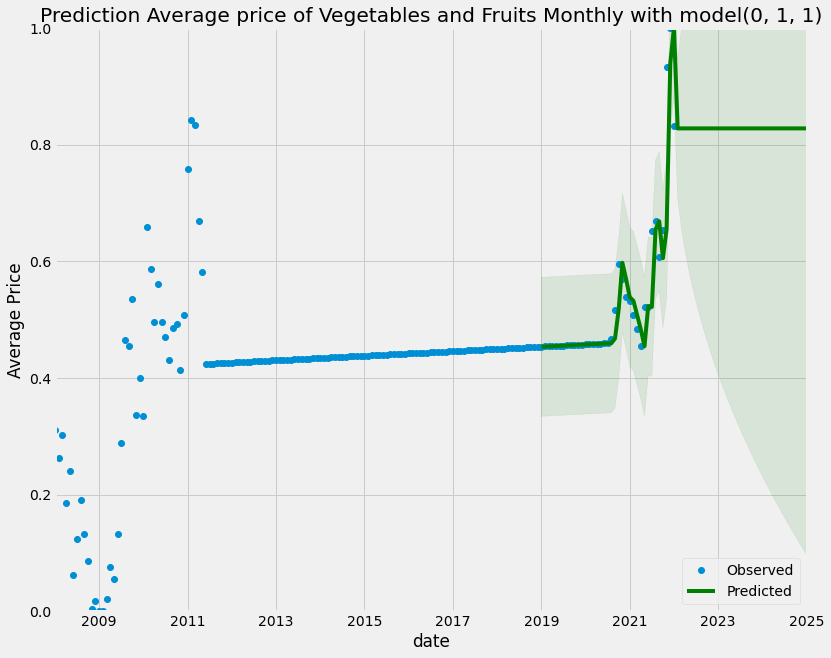

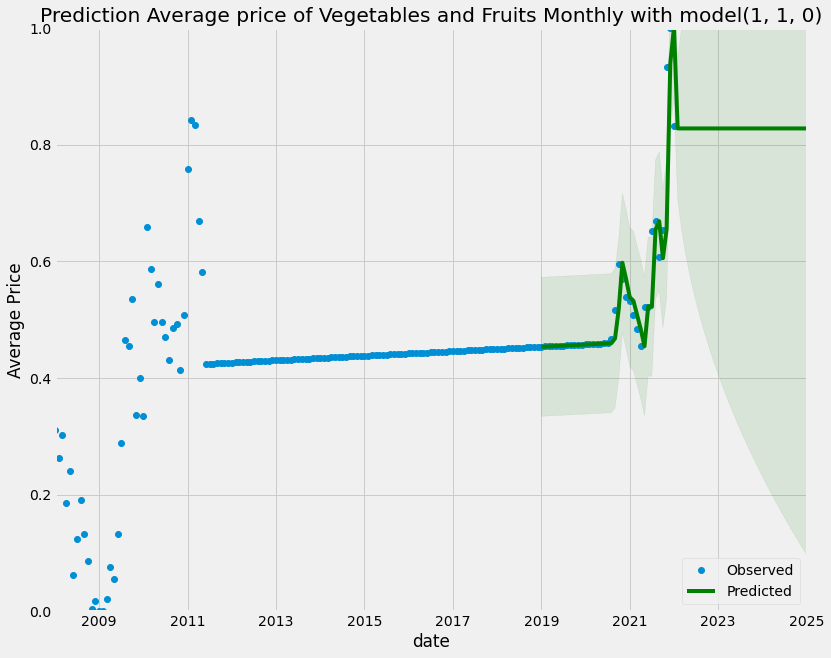

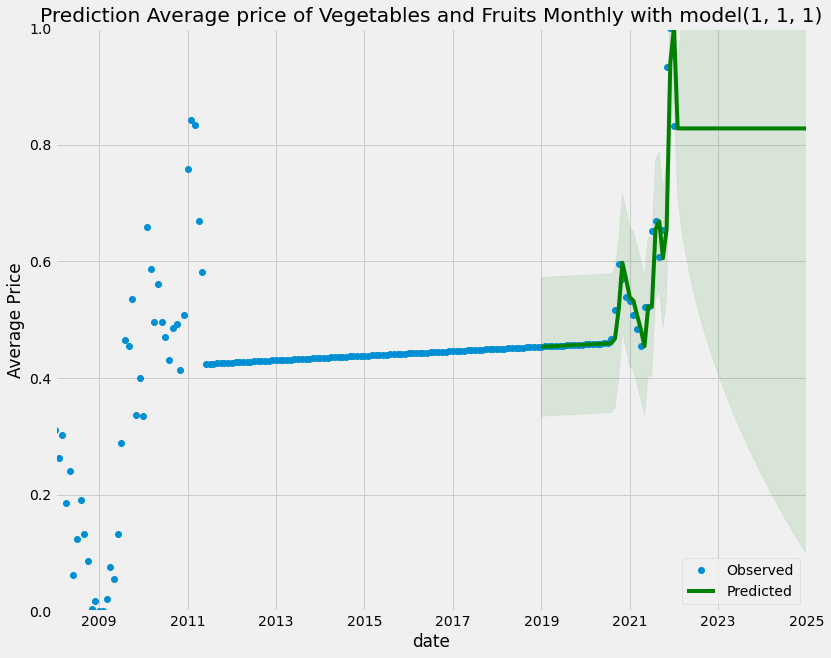

In [29]:
DVFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DVFM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Vegetables and Fruits Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DVFM_models.append(model)

Now we choose (0,1,0)

In [30]:
DVFM_model = DVFM_models[0]

In [31]:
DVFM_pred_normalized = DVFM_model.predict(pred_st_date, pred_end_date)
DVFM_pred_normalized 

2019-01-01    0.453475
2019-02-01    0.453800
2019-03-01    0.454125
2019-04-01    0.454450
2019-05-01    0.454774
                ...   
2024-09-01    0.831845
2024-10-01    0.831845
2024-11-01    0.831845
2024-12-01    0.831845
2025-01-01    0.831845
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64

We need to un-normalized the predicted value to get actual price

In [32]:
pred_date = DVFM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2019-01-01', '2019-02-01', '2019-03-01', '2019-04-01',
               '2019-05-01', '2019-06-01', '2019-07-01', '2019-08-01',
               '2019-09-01', '2019-10-01', '2019-11-01', '2019-12-01',
               '2020-01-01', '2020-02-01', '2020-03-01', '2020-04-01',
               '2020-05-01', '2020-06-01', '2020-07-01', '2020-08-01',
               '2020-09-01', '2020-10-01', '2020-11-01', '2020-12-01',
               '2021-01-01', '2021-02-01', '2021-03-01', '2021-04-01',
               '2021-05-01', '2021-06-01', '2021-07-01', '2021-08-01',
               '2021-09-01', '2021-10-01', '2021-11-01', '2021-12-01',
               '2022-01-01', '2022-02-01', '2022-03-01', '2022-04-01',
               '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01',
               '2022-09-01', '2022-10-01', '2022-11-01', '2022-12-01',
               '2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
      

In [33]:
DVFM_pred_normalized_df = pd.DataFrame(DVFM_pred_normalized)
DVFM_pred_normalized_df = DVFM_pred_normalized_df[:-1] # the last index doesn't need
DVFM_pred_normalized_df

,predicted_mean
2019-01-01,0.453475
2019-02-01,0.453800
2019-03-01,0.454125
2019-04-01,0.454450
2019-05-01,0.454774
...,...
2024-08-01,0.831845
2024-09-01,0.831845
2024-10-01,0.831845
2024-11-01,0.831845


##### Un-normalization data

In [34]:
DVFM_pred_act = scaler.inverse_transform(DVFM_pred_normalized_df)
DVFM_pred_act_df = pd.DataFrame(DVFM_pred_act)
DVFM_pred_act_df['date'] = pred_date
DVFM_pred_act_df.columns = ['Predicted Price', 'date']
DVFM_pred_act_df.set_index('date',  inplace=True)
DVFM_pred_act_df

,Predicted Price
date,
2019-01-01,1046.651464
2019-02-01,1047.077779
2019-03-01,1047.504093
2019-04-01,1047.930408
2019-05-01,1048.356722
...,...
2024-08-01,1543.057325
2024-09-01,1543.057325
2024-10-01,1543.057325
